In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10
print("Libraries imported and theme set!")

Libraries imported and theme set!


In [7]:
import os
print("Current Working Directory:", os.getcwd())
print("Files in Directory:", os.listdir())

In [ ]:
import pandas as pd
import numpy as np


df = pd.read_excel('Telco_customer_churn.xlsx')


df['Total Charges Clean'] = pd.to_numeric(df['Total Charges'], errors='coerce').fillna(0.0)

df_cleaned = df.drop(columns=['Count', 'Country', 'State'], errors='ignore')


def categorize_tenure(months):
    if months <= 12:
        return '0-1 Year'
    elif months <= 24:
        return '1-2 Years'
    elif months <= 48:
        return '2-4 Years'
    else:
        return '4+ Years'

df_cleaned['Tenure Cohort'] = df_cleaned['Tenure Months'].apply(categorize_tenure)

addon_services = ['Online Security', 'Online Backup', 'Device Protection', 
                  'Tech Support', 'Streaming TV', 'Streaming Movies']
df_cleaned['Addon Services Count'] = df_cleaned[addon_services].apply(
    lambda row: sum(row == 'Yes'), axis=1
)

df_cleaned['Avg Monthly Spend Check'] = np.where(
    df_cleaned['Tenure Months'] > 0,
    df_cleaned['Total Charges Clean'] / df_cleaned['Tenure Months'],
    df_cleaned['Monthly Charges']
)

# Export CSV
df_cleaned.to_csv('cleaned_telco_churn.csv', index=False)
print("SUCCESS: 'cleaned_telco_churn.csv' generated!")

SUCCESS: 'cleaned_telco_churn.csv' generated!


In [9]:
df = pd.read_csv('cleaned_telco_churn.csv')

total_customers = len(df)
churned_customers = int(df['Churn Value'].sum())
churn_rate = (churned_customers / total_customers) * 100
lost_mrr = df[df['Churn Value'] == 1]['Monthly Charges'].sum()
total_mrr = df['Monthly Charges'].sum()
lost_mrr_pct = (lost_mrr / total_mrr) * 100

print(f"=== EXECUTIVE KPIS ===")
print(f"Total Customers:          {total_customers:,}")
print(f"Churned Accounts:         {churned_customers:,}")
print(f"Overall Churn Rate:       {churn_rate:.2f}%")
print(f"Lost Monthly Revenue:     ${lost_mrr:,.2f} ({lost_mrr_pct:.1f}% of total MRR)")

=== EXECUTIVE KPIS ===
Total Customers:          7,043
Churned Accounts:         1,869
Overall Churn Rate:       26.54%
Lost Monthly Revenue:     $139,130.85 (30.5% of total MRR)


In [ ]:

cat_features = ['Contract', 'Internet Service', 'Payment Method', 'Tech Support', 'Online Security', 'Senior Citizen']
chi2_results = []

for col in cat_features:
    contingency = pd.crosstab(df[col], df['Churn Value'])
    chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
    chi2_results.append({
        'Feature': col,
        'Chi2 Statistic': round(chi2, 2),
        'p-value': f"{p_val:.4e}",
        'Significant (p < 0.05)': p_val < 0.05
    })

print("--- Categorical Feature Significance (Chi-Square) ---")
display(pd.DataFrame(chi2_results))


num_features = ['Monthly Charges', 'Tenure Months', 'CLTV']
t_results = []

for col in num_features:
    churn_group = df[df['Churn Value'] == 1][col]
    stay_group = df[df['Churn Value'] == 0][col]
    t_stat, p_val = stats.ttest_ind(churn_group, stay_group, equal_var=False)
    t_results.append({
        'Metric': col,
        'T-Statistic': round(t_stat, 2),
        'p-value': f"{p_val:.4e}",
        'Significant (p < 0.05)': p_val < 0.05
    })

print("\n--- Continuous Metric Significance (T-Test) ---")
display(pd.DataFrame(t_results))

--- Categorical Feature Significance (Chi-Square) ---


,Feature,Chi2 Statistic,p-value,Significant (p < 0.05)
0,Contract,1184.60,5.8630e-258,True
1,Internet Service,732.31,9.5718e-160,True
2,Payment Method,648.14,3.6824e-140,True
3,Tech Support,828.20,1.4431e-180,True
4,Online Security,850.00,2.6611e-185,True
5,Senior Citizen,159.43,1.5101e-36,True



--- Continuous Metric Significance (T-Test) ---


,Metric,T-Statistic,p-value,Significant (p < 0.05)
0,Monthly Charges,18.41,8.5924e-73,True
1,Tenure Months,-34.82,1.1955e-232,True
2,CLTV,-10.69,3.0489e-26,True


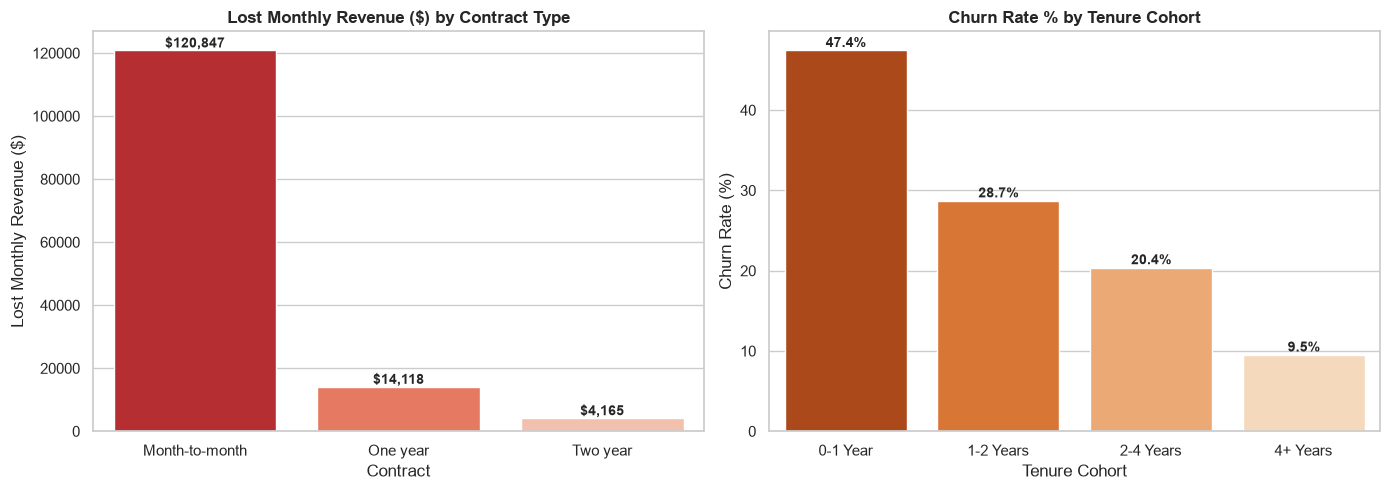

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


contract_mrr = df[df['Churn Value'] == 1].groupby('Contract')['Monthly Charges'].sum().reset_index()
sns.barplot(data=contract_mrr, x='Contract', y='Monthly Charges', ax=axes[0], palette='Reds_r')
axes[0].set_title('Lost Monthly Revenue ($) by Contract Type', fontweight='bold')
axes[0].set_ylabel('Lost Monthly Revenue ($)')
for p in axes[0].patches:
    axes[0].annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')


cohort_order = ['0-1 Year', '1-2 Years', '2-4 Years', '4+ Years']
tenure_churn = df.groupby('Tenure Cohort')['Churn Value'].mean().reset_index()
tenure_churn['Churn_Rate_%'] = tenure_churn['Churn Value'] * 100
tenure_churn['Tenure Cohort'] = pd.Categorical(tenure_churn['Tenure Cohort'], categories=cohort_order, ordered=True)
tenure_churn = tenure_churn.sort_values('Tenure Cohort')

sns.barplot(data=tenure_churn, x='Tenure Cohort', y='Churn_Rate_%', ax=axes[1], palette='Oranges_r')
axes[1].set_title('Churn Rate % by Tenure Cohort', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

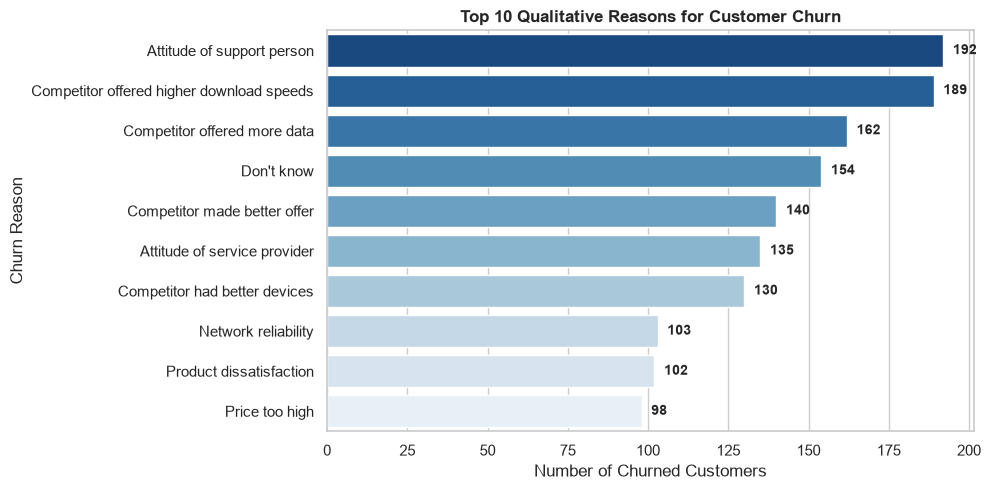

In [12]:
top_reasons = df[df['Churn Value'] == 1]['Churn Reason'].value_counts().head(10).reset_index()
top_reasons.columns = ['Churn Reason', 'Customer Count']

plt.figure(figsize=(10, 5))
sns.barplot(data=top_reasons, y='Churn Reason', x='Customer Count', palette='Blues_r')
plt.title('Top 10 Qualitative Reasons for Customer Churn', fontweight='bold')
plt.xlabel('Number of Churned Customers')
plt.ylabel('Churn Reason')

for index, value in enumerate(top_reasons['Customer Count']):
    plt.text(value + 3, index, str(value), va='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd


df = pd.read_csv('cleaned_telco_churn.csv')


df['Churn Reason'] = df['Churn Reason'].fillna('N/A - Retained')


df.to_csv('cleaned_telco_churn.csv', index=False)
print("Updated cleaned_telco_churn.csv: NULL values in Churn Reason replaced successfully!")

Updated cleaned_telco_churn.csv: NULL values in Churn Reason replaced successfully!
